## Home Price Data EDA ##

In [3]:
# Importing neccesary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [19]:
# load training and testing data
train = pd.read_csv('/Users/ryleighbergmann/House_Prices/Original Data/train.csv')
test = pd.read_csv('/Users/ryleighbergmann/House_Prices/Original Data/test.csv')

In [38]:
# Counting rows and columns of the data
print("Training data:", train.shape)

Training data: (1460, 81)


In [9]:
print("Duplicate rows (train):", train.duplicated().sum())

Duplicate rows: 0


In [13]:
# list of column names
print(train.columns.tolist())

['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'PoolQC'

In [21]:
# List sorted by greatest to least null values
print(train.isnull().sum().sort_values(ascending=False).head(15))

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageYrBlt       81
GarageCond        81
GarageType        81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtQual          37
dtype: int64


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


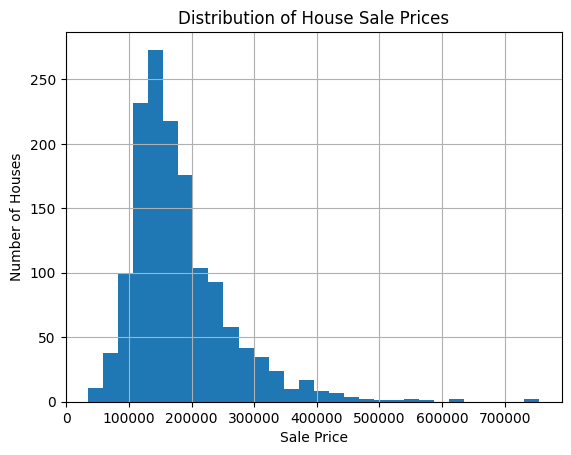

In [25]:
print(train["SalePrice"].describe())

# Plot the distribution of sale prices
train["SalePrice"].hist(bins=30)
plt.xlabel("Sale Price")
plt.ylabel("Number of Houses")
plt.title("Distribution of House Sale Prices")
plt.show()

In [31]:
missing_count_train = train.isnull().sum()

# Calculate percentage of missing values
missing_percent_train = (missing_count_train / len(train)) * 100

# Combine results into a table
missing_table = pd.DataFrame({
    "Missing Count Train": missing_count_train,
    "Missing Percent Train": missing_percent_train
})

# Show columns with missing values, highest percentage first
missing_table = missing_table[missing_table["Missing Count Train"] > 0]
missing_table.sort_values("Missing Percent Train", ascending=False).head(20)

,Missing Count Train,Missing Percent Train
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


In [11]:
# Categorical columns where missing means the feature does not exist
none_columns = [
    "Alley",
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
    "FireplaceQu",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "PoolQC",
    "Fence",
    "MiscFeature"
]

# Numerical columns where missing means the feature is absent
zero_columns = [
    "MasVnrArea",
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "BsmtFullBath",
    "BsmtHalfBath",
    "GarageCars",
    "GarageArea"
]

In [13]:
# Fill missing categorical values with "None"
for column in none_columns:
    if column in train.columns:
        train[column] = train[column].fillna("None")

    if column in test.columns:
        test[column] = test[column].fillna("None")

# Fill missing numerical values with 0
for column in zero_columns:
    if column in train.columns:
        train[column] = train[column].fillna(0)

    if column in test.columns:
        test[column] = test[column].fillna(0)

In [15]:
remaining_missing = train.isnull().sum()

remaining_missing = remaining_missing[remaining_missing > 0]

remaining_missing.sort_values(ascending=False)

MasVnrType     872
LotFrontage    259
GarageYrBlt     81
Electrical       1
dtype: int64

In [17]:
test.isnull().sum().sort_values(ascending=False).head(20)

MasVnrType      894
LotFrontage     227
GarageYrBlt      78
MSZoning          4
Utilities         2
Functional        2
Exterior1st       1
SaleType          1
Exterior2nd       1
KitchenQual       1
TotRmsAbvGrd      0
GarageFinish      0
GarageType        0
FireplaceQu       0
Fireplaces        0
Id                0
KitchenAbvGr      0
HalfBath          0
FullBath          0
BsmtHalfBath      0
dtype: int64

In [53]:
# Save cleaned training data as a new CSV
train.to_csv("cleaned_train.csv", index=False)

### Test Data Cleaning

In [40]:
print("Test data:", test.shape)
print("Duplicate rows(test):", test.duplicated().sum())

Test data: (1459, 80)
Duplicate rows(test): 0


In [42]:
print(test.columns.tolist())

['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'PoolQC'

In [44]:
print(test.isnull().sum().sort_values(ascending=False).head(15))

PoolQC          1456
MiscFeature     1408
Alley           1352
Fence           1169
MasVnrType       894
FireplaceQu      730
LotFrontage      227
GarageYrBlt       78
GarageQual        78
GarageFinish      78
GarageCond        78
GarageType        76
BsmtCond          45
BsmtQual          44
BsmtExposure      44
dtype: int64


In [35]:
missing_count_test = test.isnull().sum()

# Calculate percentage of missing values
missing_percent = (missing_count_test / len(test)) * 100

# Combine results into a table
missing_table = pd.DataFrame({
    "Missing Count Test": missing_count_test,
    "Missing Percent Test": missing_percent
})

# Show columns with missing values, highest percentage first
missing_table = missing_table[missing_table["Missing Count Test"] > 0]
missing_table.sort_values("Missing Percent Test", ascending=False).head(20)

,Missing Count Test,Missing Percent Test
PoolQC,1456,99.794380
MiscFeature,1408,96.504455
Alley,1352,92.666210
Fence,1169,80.123372
MasVnrType,894,61.274846
FireplaceQu,730,50.034270
LotFrontage,227,15.558602
GarageCond,78,5.346127
GarageYrBlt,78,5.346127
GarageQual,78,5.346127


In [47]:
for column in none_columns:
    if column in test.columns:
        test[column] = test[column].fillna("None")

for column in zero_columns:
    if column in test.columns:
        test[column] = test[column].fillna(0)

In [49]:
test_missing = test.isnull().sum()

test_missing = test_missing[test_missing > 0]

test_missing.sort_values(ascending=False)

MasVnrType     894
LotFrontage    227
GarageYrBlt     78
MSZoning         4
Utilities        2
Functional       2
Exterior1st      1
Exterior2nd      1
KitchenQual      1
SaleType         1
dtype: int64

In [51]:
test.to_csv("cleaned_test.csv", index=False)